# Dengue no Brasil (2000–2026): análise exploratória

**Autor:** Marcelo de Moura Maia Júnior · **Instituição:** Centro Universitário La Salle do Rio de Janeiro (Unilasalle-RJ)
**Curso:** Bacharelado em Sistemas de Informação — 6º período · **Disciplina:** Linguagens de Programação (Análise e Visualização de Dados com Python) — 2026.2

Este notebook explora as tabelas geradas por `src/etl.py` a partir das notificações de dengue do SINAN e da população residente do IBGE. A análise é organizada em torno de três perguntas de pesquisa:

- **RQ1 — Tempo:** como a incidência de dengue evoluiu entre 2000 e 2026, qual é o padrão sazonal ao longo do ano e em que medida a epidemia de 2024 se afasta do comportamento histórico?
- **RQ2 — Espaço:** como os casos se distribuem entre regiões, estados e municípios, quão concentrada é essa distribuição e houve expansão para áreas antes pouco afetadas, como a Região Sul?
- **RQ3 — Pessoas e gravidade:** como idade e sexo se relacionam com a ocorrência, a hospitalização, a gravidade e o óbito, e quais sorotipos do vírus circularam no período?

**Como executar:** a partir da raiz do repositório, depois de `python -m src.download` e `python -m src.etl`, abra este notebook com `jupyter notebook notebooks/analise_exploratoria.ipynb`. As figuras são exportadas para `docs/assets/`.

## 0. Preparação e qualidade dos dados

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from matplotlib.colors import LogNorm
from plotly.subplots import make_subplots
from scipy import stats

from src import config, metricas, populacao
from src import visualizacao as viz

viz.configurar_matplotlib()
viz.configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda valor: viz.formatar_numero(valor, 2))

ANOS_COMPLETOS = [ano for ano in config.YEARS if ano not in config.PARTIAL_YEARS]
metricas_artigo = {}

In [2]:
NOMES_TABELAS = [
    "casos_semana_uf",
    "casos_ano_uf",
    "casos_ano_municipio",
    "perfil_demografico",
    "casos_raca_cor",
    "sorotipos",
    "completude",
]
tabelas = {nome: pd.read_parquet(config.PROCESSED_DIR / f"{nome}.parquet") for nome in NOMES_TABELAS}
log_etl = pd.read_csv(config.PROCESSED_DIR / "etl_log.csv")
estados = populacao.load_states()
pop_uf = populacao.load_population("uf").rename(columns={"ano": "ano_epi"})
pop_municipio = populacao.load_population("municipio").rename(columns={"ano": "ano_epi"})

pd.DataFrame(
    {
        "linhas": {nome: len(tabela) for nome, tabela in tabelas.items()},
        "colunas": {nome: tabela.shape[1] for nome, tabela in tabelas.items()},
    }
)

,linhas,colunas
casos_semana_uf,36665,11
casos_ano_uf,728,17
casos_ano_municipio,106572,15
perfil_demografico,20995,10
casos_raca_cor,161,8
sorotipos,1436,4
completude,27,10


### 0.1 Rastreabilidade do tratamento

O registro `etl_log.csv` contabiliza, para cada arquivo anual do SINAN, quantas linhas foram lidas, removidas (e por qual motivo) e mantidas. A soma abaixo reconcilia os 27 arquivos brutos com as tabelas analíticas: nenhuma linha some sem justificativa.

In [3]:
colunas_fluxo = [
    "registros_lidos",
    "removidos_duplicidade",
    "removidos_descartados",
    "removidos_chikungunya",
    "removidos_sem_data",
    "casos_provaveis",
    "fora_do_periodo",
    "casos_no_periodo",
]
fluxo = log_etl[colunas_fluxo].sum()
assert fluxo["registros_lidos"] - fluxo[[c for c in colunas_fluxo if c.startswith("removidos")]].sum() == fluxo["casos_provaveis"]
assert fluxo["casos_provaveis"] - fluxo["fora_do_periodo"] == fluxo["casos_no_periodo"]
assert tabelas["completude"]["registros"].sum() == fluxo["casos_no_periodo"]

sem_uf = fluxo["casos_no_periodo"] - tabelas["casos_ano_uf"]["casos"].sum()
fluxo_formatado = fluxo.map(viz.formatar_numero).to_frame("registros")
fluxo_formatado.loc["sem_uf_de_residencia_valida"] = viz.formatar_numero(sem_uf)
metricas_artigo["registros_lidos"] = int(fluxo["registros_lidos"])
metricas_artigo["casos_provaveis_periodo"] = int(fluxo["casos_no_periodo"])
metricas_artigo["removidos_descartados"] = int(fluxo["removidos_descartados"])
metricas_artigo["removidos_duplicidade"] = int(fluxo["removidos_duplicidade"])
fluxo_formatado

,registros
registros_lidos,32.512.002
removidos_duplicidade,430
removidos_descartados,6.146.531
removidos_chikungunya,0
removidos_sem_data,0
casos_provaveis,26.365.041
fora_do_periodo,102
casos_no_periodo,26.364.939
sem_uf_de_residencia_valida,3.860


In [4]:
log_etl[["ano_arquivo", "registros_lidos", "removidos_descartados", "casos_provaveis", "dt_sintomas_imputada", "semana_divergente", "idade_ausente"]]

,ano_arquivo,registros_lidos,removidos_descartados,casos_provaveis,dt_sintomas_imputada,semana_divergente,idade_ausente
0,2000,172855,36131,136724,12,815,114
1,2001,488590,101584,387006,100,201,2176
2,2002,897093,193604,703489,819,2715,5125
3,2003,416609,137309,279300,763,2165,1534
4,2004,136867,64493,72374,220,418,58
5,2005,261501,110355,151146,435,2095,1282
6,2006,411022,144466,266556,702,5375,1184
7,2007,717097,216505,500581,267,270,31
8,2008,919324,281657,637652,1627,2,334
9,2009,600658,189121,411199,1402,0,2


Dois pontos chamam atenção no registro:

- **Casos descartados:** de 2014 a 2015 e de 2022 a 2026 os arquivos publicados já vêm sem os casos descartados (a coluna de removidos é zero). Por isso a análise usa sempre **casos prováveis** (todos os notificados, exceto os descartados), a definição adotada pelo Ministério da Saúde, que é comparável entre todos os anos.
- **Semana epidemiológica:** a semana calculada a partir da data dos sintomas coincide com a semana gravada pelo SINAN em mais de 99% dos registros; as divergências se concentram nos arquivos antigos, anteriores a 2014.

### 0.2 Completude dos campos

A qualidade do preenchimento muda muito ao longo de 27 anos. Campos com baixa completude em um período não podem sustentar comparações naquele período.

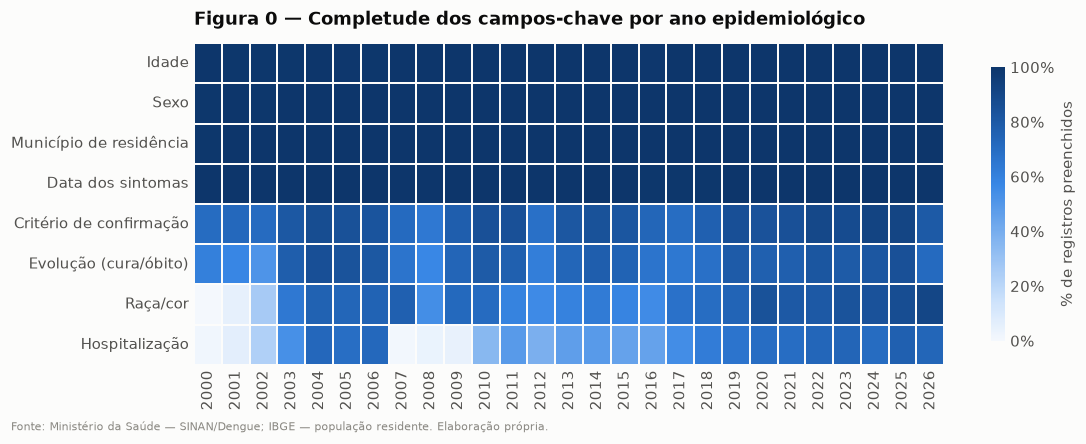

In [5]:
completude = tabelas["completude"].set_index("ano_epi")
rotulos_campos = {
    "pct_idade": "Idade",
    "pct_sexo": "Sexo",
    "pct_municipio_residencia": "Município de residência",
    "pct_dt_sintomas_original": "Data dos sintomas",
    "pct_criterio": "Critério de confirmação",
    "pct_evolucao": "Evolução (cura/óbito)",
    "pct_raca": "Raça/cor",
    "pct_hospitalizacao": "Hospitalização",
}
matriz_completude = completude[list(rotulos_campos)].rename(columns=rotulos_campos).T

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(
    matriz_completude,
    cmap=viz.MAPA_SEQUENCIAL,
    vmin=0,
    vmax=100,
    linewidths=1,
    linecolor=viz.SUPERFICIE,
    cbar_kws={"label": "% de registros preenchidos", "format": viz.EIXO_PERCENTUAL, "shrink": 0.85},
    ax=ax,
)
ax.set_title("Figura 0 — Completude dos campos-chave por ano epidemiológico")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=90)
ax.grid(False)
viz.salvar_figura(fig, "fig00_completude")
plt.show()

In [6]:
matriz_completude.loc[:, [2000, 2003, 2009, 2014, 2019, 2024, 2025]]

ano_epi,2000,2003,2009,2014,2019,2024,2025
Idade,"99,92","99,45","100,00","99,98","99,97","99,99","100,00"
Sexo,"99,60","99,96","99,98","99,84","99,87","99,85","99,93"
Município de residência,"99,56","99,94","99,99","99,99","100,00","100,00","100,00"
Data dos sintomas,"99,99","99,73","99,67","100,00","99,73","100,00","100,00"
Critério de confirmação,"70,65","80,76","77,66","84,24","85,32","92,18","91,15"
Evolução (cura/óbito),"60,58","77,98","74,12","77,45","79,21","81,42","84,84"
Raça/cor,"0,26","64,07","72,26","63,17","74,31","83,82","86,65"
Hospitalização,"1,78","53,38","4,30","48,67","66,08","70,64","76,20"


Idade, sexo, município e data dos sintomas estão praticamente completos em todo o período e sustentam a análise temporal, geográfica e demográfica. **Hospitalização** só passa de 30% de preenchimento a partir de 2010 e **raça/cor** oscila entre 55% e 90%; por isso, as proporções de hospitalização usam como denominador apenas os registros com o campo preenchido, e a análise de perfil (RQ3) se restringe a 2014–2025, período com a classificação de casos atual e preenchimento mais estável.

## 1. RQ1 — Evolução temporal e sazonalidade

In [7]:
anual = (
    tabelas["casos_ano_uf"]
    .groupby("ano_epi")[["casos", "casos_graves", "obitos", "populacao"]]
    .sum()
    .rename(columns={"populacao": "populacao_uf"})
)
anual["populacao"] = pop_uf.groupby("ano_epi")["populacao"].sum()
anual["incidencia"] = metricas.incidencia(anual["casos"], anual["populacao"])
anual["parcial"] = anual.index.isin(config.PARTIAL_YEARS)
anual[["casos", "obitos", "populacao", "incidencia", "parcial"]]

,casos,obitos,populacao,incidencia,parcial
ano_epi,,,,,
2000,136824,36,169872859,"80,54",False
2001,388560,154,172385826,"225,40",False
2002,701262,330,174632960,"401,56",False
2003,279455,195,176871437,"158,00",False
2004,72309,46,181569056,"39,82",False
2005,151344,141,184184264,"82,17",False
2006,267553,253,186770562,"143,25",False
2007,500771,327,188187786,"266,10",False
2008,638192,582,189605006,"336,59",False


In [8]:
incidencia_completa = anual.loc[ANOS_COMPLETOS, "incidencia"]
resumo_anual = metricas.resumo_descritivo(incidencia_completa)
resumo_anual.to_frame("incidência anual (por 100 mil)")

,incidência anual (por 100 mil)
n,"26,00"
media,"490,11"
mediana,"323,01"
desvio_padrao,"588,18"
coef_variacao,"1,20"
minimo,"39,82"
q1,"173,43"
q3,"715,92"
maximo,"3.088,17"
assimetria,"3,66"


In [9]:
atipicos = pd.DataFrame(
    {
        "incidencia": incidencia_completa,
        "escore_robusto": metricas.escore_robusto(incidencia_completa),
        "atipico_iqr": metricas.atipicos_iqr(incidencia_completa),
        "atipico_robusto": metricas.atipicos_robustos(incidencia_completa),
    }
)
maior_anterior = incidencia_completa.loc[: 2023].max()
ano_maior_anterior = int(incidencia_completa.loc[: 2023].idxmax())
razao_2024 = incidencia_completa[2024] / maior_anterior

metricas_artigo.update(
    {
        "casos_2024": int(anual.loc[2024, "casos"]),
        "incidencia_2024": round(float(anual.loc[2024, "incidencia"]), 1),
        "obitos_2024": int(anual.loc[2024, "obitos"]),
        "maior_incidencia_anterior": round(float(maior_anterior), 1),
        "ano_maior_incidencia_anterior": ano_maior_anterior,
        "razao_2024_recorde_anterior": round(float(razao_2024), 2),
        "incidencia_mediana_anual": round(float(resumo_anual["mediana"]), 1),
        "coef_variacao_incidencia_anual": round(float(resumo_anual["coef_variacao"]), 2),
        "escore_robusto_2024": round(float(atipicos.loc[2024, "escore_robusto"]), 1),
    }
)
print(f"2024: {viz.formatar_numero(incidencia_completa[2024], 1)} casos por 100 mil — "
      f"{viz.formatar_numero(razao_2024, 1)} vezes o maior valor anterior ({ano_maior_anterior}).")
atipicos.sort_values("escore_robusto", ascending=False).head(6)

2024: 3.088,2 casos por 100 mil — 3,8 vezes o maior valor anterior (2015).


,incidencia,escore_robusto,atipico_iqr,atipico_robusto
ano_epi,,,,
2024,"3.088,17","9,31",True,True
2015,"806,20","1,63",False,False
2023,"791,95","1,58",False,False
2025,"769,68","1,50",False,False
2019,"740,15","1,40",False,False
2013,"729,59","1,37",False,False


A incidência anual tem distribuição fortemente assimétrica: a mediana fica em torno de 300 casos por 100 mil habitantes, mas o desvio-padrão é maior que a média (coeficiente de variação acima de 1). Pelos dois critérios de valor atípico — a regra do intervalo interquartil (Tukey) e o escore-z modificado baseado na mediana (Iglewicz e Hoaglin), que não é distorcido pelos próprios extremos — **2024 é o único ano atípico**, com incidência quase quatro vezes maior que o recorde anterior, de 2015.

In [10]:
cores_barras = [viz.NEUTRO if parcial else viz.CATEGORICA[0] for parcial in anual["parcial"]]
fig = go.Figure(
    go.Bar(
        x=anual.index,
        y=anual["incidencia"],
        marker={"color": cores_barras, "line": {"width": 0}},
        customdata=np.column_stack([anual["casos"], anual["obitos"]]),
        hovertemplate=(
            "<b>%{x}</b><br>Incidência: %{y:,.1f} por 100 mil hab.<br>"
            "Casos prováveis: %{customdata[0]:,.0f}<br>Óbitos: %{customdata[1]:,.0f}<extra></extra>"
        ),
    )
)
fig.add_annotation(
    x=2024, y=anual.loc[2024, "incidencia"],
    text=f"<b>{viz.formatar_numero(anual.loc[2024, 'incidencia'], 0)}</b>",
    showarrow=False, yshift=14, font={"size": 12},
)
fig.add_annotation(
    x=2026, y=anual.loc[2026, "incidencia"], text="2026<br>parcial",
    showarrow=False, yshift=22, font={"size": 11, "color": viz.TINTA_SECUNDARIA},
)
fig.update_layout(
    title="Figura 1 — Incidência anual de dengue no Brasil, 2000–2026",
    yaxis={"title": "Casos prováveis por 100 mil habitantes", "tickformat": ",.0f"},
    xaxis={"range": [1999.4, 2026.6], "tickangle": 0},
    bargap=0.25,
    hovermode="closest",
    height=480,
    showlegend=False,
)
viz.salvar_interativo(fig, "fig01_incidencia_anual")
fig.show()

In [11]:
semanal = tabelas["casos_semana_uf"].groupby(["ano_epi", "semana_epi"], as_index=False)["casos"].sum()
semanal = semanal.merge(pop_uf.groupby("ano_epi", as_index=False)["populacao"].sum(), on="ano_epi")
semanal["incidencia"] = metricas.incidencia(semanal["casos"], semanal["populacao"])

quatro_jan = pd.to_datetime(semanal["ano_epi"].astype(str) + "-01-04")
inicio_ano_epi = quatro_jan - pd.to_timedelta((quatro_jan.dt.day_of_week + 1) % 7, unit="D")
semanal["inicio_semana"] = inicio_ano_epi + pd.to_timedelta((semanal["semana_epi"].astype("int64") - 1) * 7, unit="D")
semanal.tail()

,ano_epi,semana_epi,casos,populacao,incidencia,inicio_semana
1391,2026,35,7013,214211951,"3,27",2026-08-30
1392,2026,36,7014,214211951,"3,27",2026-09-06
1393,2026,37,7390,214211951,"3,45",2026-09-13
1394,2026,38,7483,214211951,"3,49",2026-09-20
1395,2026,39,3445,214211951,"1,61",2026-09-27


In [12]:
fig = go.Figure(
    go.Scatter(
        x=semanal["inicio_semana"],
        y=semanal["incidencia"],
        mode="lines",
        line={"color": viz.CATEGORICA[0], "width": 1.6},
        customdata=semanal[["semana_epi", "ano_epi", "casos"]].to_numpy(),
        hovertemplate=(
            "Semana %{customdata[0]} de %{customdata[1]}<br>"
            "Incidência: %{y:,.2f} por 100 mil hab.<br>Casos: %{customdata[2]:,.0f}<extra></extra>"
        ),
    )
)
fig.update_layout(
    title="Figura 2 — Incidência semanal de dengue no Brasil, 2000–2026",
    yaxis_title="Casos prováveis por 100 mil hab. na semana",
    xaxis={"rangeslider": {"visible": True, "thickness": 0.08}, "tickformat": "%Y", "type": "date"},
    hovermode="closest",
    height=520,
    showlegend=False,
)
viz.salvar_interativo(fig, "fig02_incidencia_semanal")
fig.show()

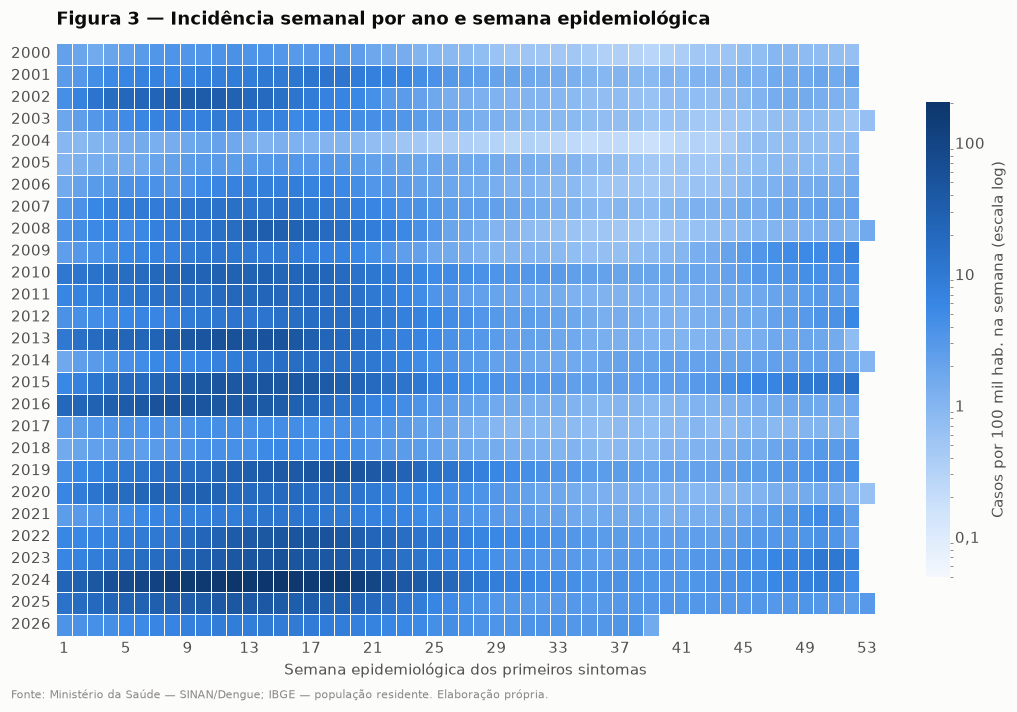

In [13]:
matriz_semanal = semanal.pivot(index="ano_epi", columns="semana_epi", values="incidencia")

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    matriz_semanal,
    cmap=viz.MAPA_SEQUENCIAL,
    norm=LogNorm(vmin=0.05, vmax=matriz_semanal.max().max()),
    linewidths=0.4,
    linecolor=viz.SUPERFICIE,
    cbar_kws={"label": "Casos por 100 mil hab. na semana (escala log)", "shrink": 0.8, "ticks": [0.1, 1, 10, 100], "format": plt.FuncFormatter(lambda valor, _: viz.formatar_numero(valor, 1 if valor < 1 else 0))},
    ax=ax,
)
ax.set_title("Figura 3 — Incidência semanal por ano e semana epidemiológica")
ax.set_xlabel("Semana epidemiológica dos primeiros sintomas")
ax.set_ylabel("")
ax.set_xticks(np.arange(0, 53, 4) + 0.5, labels=range(1, 54, 4), rotation=0)
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
viz.salvar_figura(fig, "fig03_sazonalidade")
plt.show()

In [14]:
completas = semanal[semanal["ano_epi"].isin(ANOS_COMPLETOS)]
picos = completas.loc[completas.groupby("ano_epi")["casos"].idxmax(), ["ano_epi", "semana_epi", "inicio_semana", "incidencia"]]
casos_por_semana = completas.groupby("semana_epi")["casos"].sum()
pct_semanas_8_20 = casos_por_semana.loc[8:20].sum() / casos_por_semana.sum() * 100
pct_primeiro_semestre = casos_por_semana.loc[1:26].sum() / casos_por_semana.sum() * 100

metricas_artigo.update(
    {
        "semana_pico_mediana": int(picos["semana_epi"].median()),
        "semana_pico_min": int(picos["semana_epi"].min()),
        "semana_pico_max": int(picos["semana_epi"].max()),
        "pct_casos_semanas_8_20": round(float(pct_semanas_8_20), 1),
        "pct_casos_semanas_1_26": round(float(pct_primeiro_semestre), 1),
    }
)
print(f"Semana de pico: mediana {int(picos['semana_epi'].median())} "
      f"(entre {picos['semana_epi'].min()} e {picos['semana_epi'].max()}).")
print(f"Casos entre as semanas 8 e 20: {viz.formatar_percentual(pct_semanas_8_20)}; "
      f"no primeiro semestre: {viz.formatar_percentual(pct_primeiro_semestre)}.")
picos.set_index("ano_epi")["semana_epi"].to_frame("semana de pico").T

Semana de pico: mediana 14 (entre 8 e 19).
Casos entre as semanas 8 e 20: 63,3%; no primeiro semestre: 89,0%.


ano_epi,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
semana de pico,12,18,10,11,11,15,16,15,14,11,14,14,16,11,17,14,8,16,15,19,10,14,18,15,12,12


A sazonalidade é marcada e estável: em todos os 26 anos completos o pico ocorre entre o fim do verão e o outono, e cerca de dois terços dos casos se concentram entre as semanas 8 e 20 (aproximadamente de fevereiro a meados de maio), período de chuvas e calor que favorece a reprodução do *Aedes aegypti*. A Figura 3 mostra que a "mancha" sazonal se repete ano a ano, ganhando intensidade nos anos epidêmicos (2002, 2008, 2010, 2013, 2015–2016, 2019, 2022–2025).

### 1.1 Canal endêmico

O canal endêmico é a ferramenta usada pela vigilância epidemiológica para decidir se a incidência de uma semana está acima do esperado. Para cada semana, calculam-se o primeiro quartil, a mediana e o terceiro quartil da incidência nos anos de referência (aqui, 2017 a 2023, os sete anos anteriores à epidemia). Valores acima do terceiro quartil indicam zona de alerta ou epidemia.

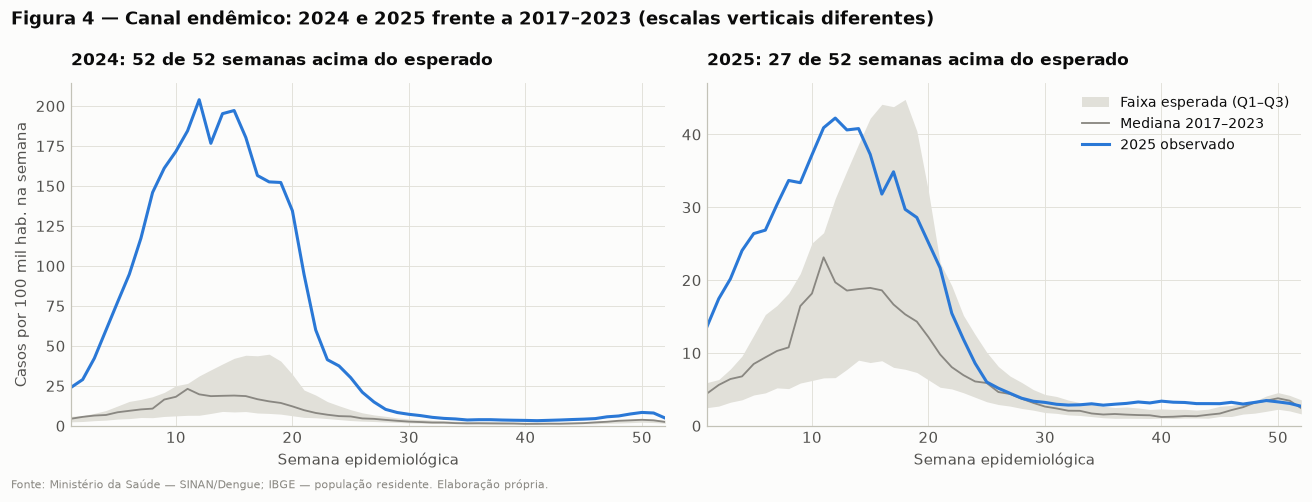

No pico de 2024 (semana 12), a incidência foi 6,5 vezes o terceiro quartil histórico.


In [15]:
ANOS_BASE = list(range(2017, 2024))
canal = metricas.canal_endemico(semanal, ANOS_BASE)
anos_comparados = [2024, 2025]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, ano in zip(eixos, anos_comparados, strict=True):
    observado = semanal[(semanal["ano_epi"] == ano) & (semanal["semana_epi"] <= 52)].set_index("semana_epi")["incidencia"]
    ax.fill_between(canal.index, canal["q1"], canal["q3"], color=viz.GRADE, linewidth=0, label="Faixa esperada (Q1–Q3)")
    ax.plot(canal.index, canal["mediana"], color=viz.TINTA_SUAVE, linewidth=1.2, label="Mediana 2017–2023")
    ax.plot(observado.index, observado.values, color=viz.CATEGORICA[0], linewidth=2, label=f"{ano} observado")
    acima = (observado > canal["q3"].reindex(observado.index)).sum()
    ax.set_title(f"{ano}: {acima} de {len(observado)} semanas acima do esperado", fontsize=11)
    ax.set_xlabel("Semana epidemiológica")
    ax.set_xlim(1, 52)
    ax.set_ylim(bottom=0)
    metricas_artigo[f"semanas_acima_q3_{ano}"] = int(acima)
eixos[0].set_ylabel("Casos por 100 mil hab. na semana")
eixos[1].legend(loc="upper right")
fig.suptitle("Figura 4 — Canal endêmico: 2024 e 2025 frente a 2017–2023 (escalas verticais diferentes)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
viz.salvar_figura(fig, "fig04_canal_endemico")
plt.show()

pico_2024 = semanal[semanal["ano_epi"] == 2024].set_index("semana_epi")["incidencia"]
razao_pico = pico_2024.max() / canal.loc[pico_2024.idxmax(), "q3"]
metricas_artigo["razao_pico_2024_q3"] = round(float(razao_pico), 1)
print(f"No pico de 2024 (semana {pico_2024.idxmax()}), a incidência foi {viz.formatar_numero(razao_pico, 1)} vezes o terceiro quartil histórico.")

**Resposta à RQ1.** A dengue no Brasil alterna anos de transmissão moderada com epidemias a cada dois ou três anos, sempre concentradas entre fevereiro e maio. A epidemia de 2024 rompe esse padrão em magnitude, não em época: o pico ocorreu na mesma janela sazonal de sempre, mas no pico a incidência semanal chegou a mais de seis vezes o limite superior do canal endêmico, e todas as semanas do ano ficaram acima da faixa esperada. Em 2025 a incidência voltou a níveis de anos epidêmicos anteriores: ficou acima do esperado no início da temporada, antecipando o pico, e dentro da faixa no restante do ano.

## 2. RQ2 — Distribuição geográfica e concentração

In [16]:
ano_uf = tabelas["casos_ano_uf"].copy()
regional = ano_uf.groupby(["ano_epi", "regiao"], observed=True)[["casos", "populacao"]].sum().reset_index()
regional["incidencia"] = metricas.incidencia(regional["casos"], regional["populacao"])
regional["participacao"] = regional["casos"] / regional.groupby("ano_epi")["casos"].transform("sum") * 100
regional.pivot(index="ano_epi", columns="regiao", values="incidencia")[viz.REGIOES].loc[[2000, 2005, 2010, 2015, 2020, 2024, 2025]]

regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
ano_epi,,,,,
2000,"203,09","147,02","54,36","46,60","4,95"
2005,"174,62","149,00","205,49","27,72","4,26"
2010,"638,76","337,39","1.546,18","597,67","154,56"
2015,"175,39","558,94","1.483,22","1.195,04","163,37"
2020,"126,70","261,90","1.196,60","336,85","926,00"
2024,"304,83","605,02","3.949,87","4.830,56","3.880,86"
2025,"208,45","176,32","956,59","1.260,24","696,94"


In [17]:
malha_ibge = json.loads((config.IBGE_RAW_DIR / "malha_uf.geojson").read_text(encoding="utf-8"))
malha = viz.preparar_malha(malha_ibge)

mapa = ano_uf[["ano_epi", "codigo_uf", "sigla_uf", "nome_uf", "casos", "obitos", "incidencia_100mil"]].copy()
mapa["log_incidencia"] = np.log10(mapa["incidencia_100mil"].clip(lower=0.1))
marcas = [1, 10, 100, 1_000, 10_000]
anos_mapa = sorted(int(ano) for ano in mapa["ano_epi"].unique())
ANO_INICIAL = 2024


def dados_ano(ano):
    recorte = mapa[mapa["ano_epi"] == ano]
    return {
        "locations": recorte["codigo_uf"].tolist(),
        "z": recorte["log_incidencia"].tolist(),
        "customdata": recorte[["nome_uf", "incidencia_100mil", "casos", "obitos"]].to_numpy().tolist(),
    }


fig = go.Figure(
    go.Choropleth(
        geojson=malha,
        featureidkey="id",
        **dados_ano(ANO_INICIAL),
        zmin=0,
        zmax=4,
        colorscale=viz.ESCALA_PLOTLY,
        marker={"line": {"color": viz.SUPERFICIE, "width": 0.8}},
        colorbar={
            "title": {"text": "Casos por<br>100 mil hab.", "side": "top"},
            "tickvals": np.log10(marcas),
            "ticktext": [viz.formatar_numero(valor) for valor in marcas],
            "thickness": 12,
            "len": 0.7,
        },
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>Incidência: %{customdata[1]:,.1f} por 100 mil hab.<br>"
            "Casos: %{customdata[2]:,.0f}<br>Óbitos: %{customdata[3]:,.0f}<extra></extra>"
        ),
    ),
)
fig.update_geos(fitbounds="locations", visible=False, bgcolor=viz.SUPERFICIE)
fig.update_layout(
    title="Figura 5 — Incidência de dengue por unidade da federação",
    height=620,
    margin={"l": 10, "r": 10, "t": 60, "b": 90},
    hovermode="closest",
    sliders=[
        {
            "active": anos_mapa.index(ANO_INICIAL),
            "currentvalue": {"prefix": "Ano: ", "font": {"size": 14}},
            "pad": {"t": 10},
            "steps": [
                {
                    "label": str(ano),
                    "method": "restyle",
                    "args": [{chave: [valor] for chave, valor in dados_ano(ano).items()}],
                }
                for ano in anos_mapa
            ],
        }
    ],
)
caminho_mapa = viz.salvar_interativo(fig, "fig05_mapa_incidencia_uf")
print(f"Tamanho do mapa interativo: {caminho_mapa.stat().st_size / 1024:,.0f} KB")
fig.show()

Tamanho do mapa interativo: 131 KB


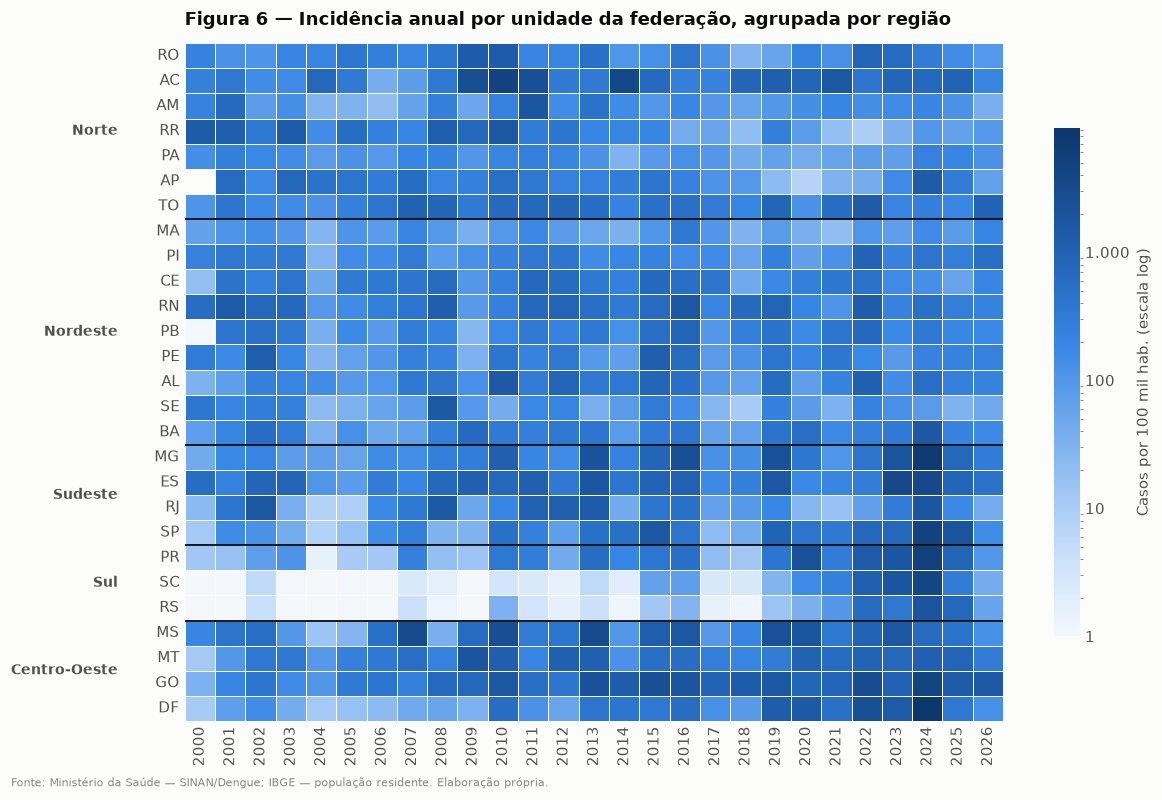

In [18]:
matriz_uf = ano_uf.pivot(index="codigo_uf", columns="ano_epi", values="incidencia_100mil").sort_index()
siglas = estados.set_index("codigo_uf").loc[matriz_uf.index, ["sigla_uf", "regiao"]]

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    matriz_uf,
    cmap=viz.MAPA_SEQUENCIAL,
    norm=LogNorm(vmin=1, vmax=matriz_uf.max().max()),
    linewidths=0.6,
    linecolor=viz.SUPERFICIE,
    yticklabels=siglas["sigla_uf"],
    cbar_kws={"label": "Casos por 100 mil hab. (escala log)", "shrink": 0.75, "ticks": [1, 10, 100, 1_000, 10_000], "format": viz.EIXO_NUMERICO},
    ax=ax,
)
limites = siglas["regiao"].ne(siglas["regiao"].shift()).to_numpy().nonzero()[0]
for posicao in limites[1:]:
    ax.axhline(posicao, color=viz.TINTA, linewidth=1.2)
for inicio, fim in zip(limites, list(limites[1:]) + [len(siglas)], strict=True):
    ax.text(-2.2, (inicio + fim) / 2, siglas["regiao"].iloc[inicio], ha="right", va="center", fontsize=9, color=viz.TINTA_SECUNDARIA, fontweight="bold")
ax.set_title("Figura 6 — Incidência anual por unidade da federação, agrupada por região")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
ax.tick_params(axis="x", rotation=90)
ax.grid(False)
viz.salvar_figura(fig, "fig06_incidencia_uf_ano")
plt.show()

In [19]:
maiores = (
    ano_uf[ano_uf["ano_epi"].isin([2002, 2008, 2013, 2015, 2019, 2024, 2025])]
    .sort_values(["ano_epi", "incidencia_100mil"], ascending=[True, False])
    .groupby("ano_epi")
    .head(3)
)
maiores.assign(posicao=maiores.groupby("ano_epi").cumcount() + 1).pivot(index="ano_epi", columns="posicao", values="sigla_uf").rename(columns=lambda p: f"{p}º")

posicao,1º,2º,3º
ano_epi,,,
2002,RJ,PE,ES
2008,RJ,SE,RR
2013,MS,GO,MG
2015,GO,SP,MS
2019,MS,MG,GO
2024,DF,MG,PR
2025,SP,GO,AC


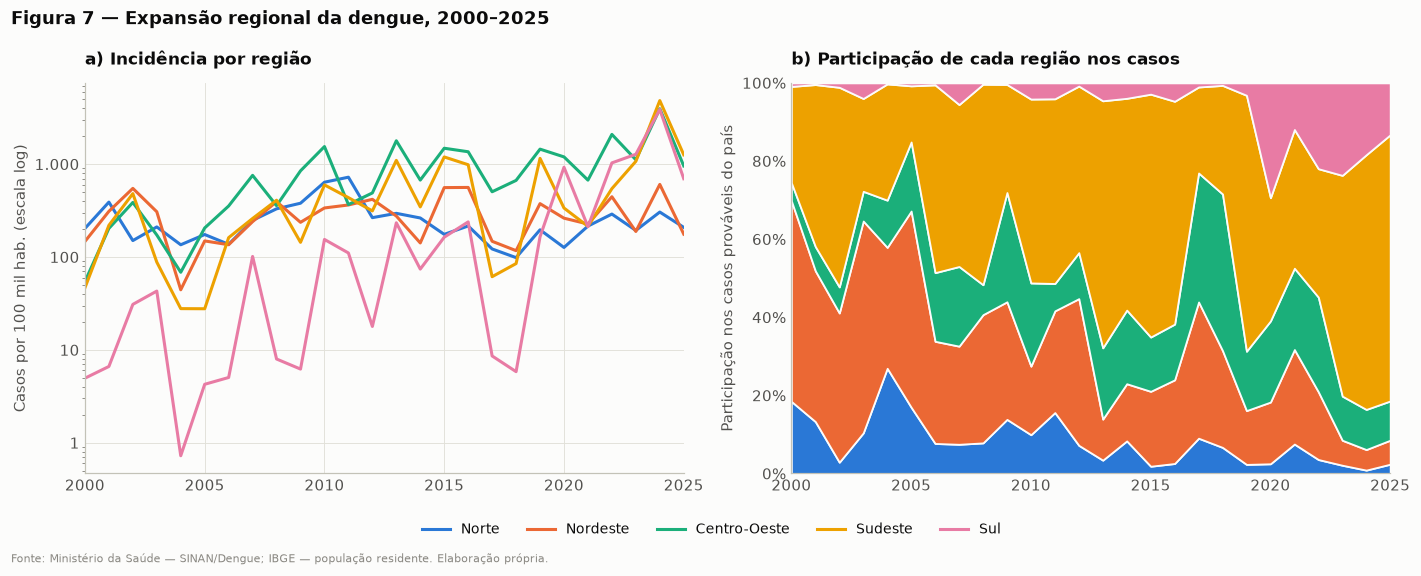

regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
ano_epi,,,,,
2000,"18,46","51,34","4,62","24,67","0,91"
2004,"26,93","30,95","12,09","29,76","0,27"
2008,"7,84","32,82","7,66","51,33","0,34"
2012,"7,21","37,56","11,77","42,64","0,83"
2016,"2,56","21,41","14,27","57,04","4,71"
2020,"2,49","15,80","20,77","31,53","29,40"
2024,"0,87","5,26","10,27","65,21","18,39"
2025,"2,39","6,14","10,04","68,15","13,28"


In [20]:
inc_regiao = regional.pivot(index="ano_epi", columns="regiao", values="incidencia")[viz.REGIOES]
part_regiao = regional.pivot(index="ano_epi", columns="regiao", values="participacao")[viz.REGIOES].loc[ANOS_COMPLETOS]

fig, (ax_inc, ax_part) = plt.subplots(1, 2, figsize=(13, 5))
for regiao in viz.REGIOES:
    serie = inc_regiao.loc[ANOS_COMPLETOS, regiao]
    ax_inc.plot(serie.index, serie.values, color=viz.CORES_REGIAO[regiao], label=regiao)
ax_inc.set_yscale("log")
ax_inc.yaxis.set_major_formatter(viz.EIXO_NUMERICO)
ax_inc.set_ylabel("Casos por 100 mil hab. (escala log)")
ax_inc.set_title("a) Incidência por região", fontsize=11)
ax_inc.set_xlim(2000, 2025)

ax_part.stackplot(
    part_regiao.index,
    part_regiao.T.to_numpy(),
    colors=[viz.CORES_REGIAO[r] for r in viz.REGIOES],
    labels=viz.REGIOES,
    edgecolor=viz.SUPERFICIE,
    linewidth=1.2,
)
ax_part.set_ylim(0, 100)
ax_part.set_xlim(2000, 2025)
ax_part.yaxis.set_major_formatter(viz.EIXO_PERCENTUAL)
ax_part.set_ylabel("Participação nos casos prováveis do país")
ax_part.set_title("b) Participação de cada região nos casos", fontsize=11)
ax_part.grid(False)
fig.suptitle("Figura 7 — Expansão regional da dengue, 2000–2025", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(*ax_inc.get_legend_handles_labels(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0))
viz.salvar_figura(fig, "fig07_regioes")
plt.show()

part_sul = part_regiao["Sul"]
metricas_artigo.update(
    {
        "participacao_sul_2004": round(float(part_sul[2004]), 1),
        "participacao_sul_2020": round(float(part_sul[2020]), 1),
        "participacao_sul_2024": round(float(part_sul[2024]), 1),
        "incidencia_sul_2000": round(float(inc_regiao.loc[2000, "Sul"]), 1),
        "incidencia_sul_2024": round(float(inc_regiao.loc[2024, "Sul"]), 1),
        "participacao_sudeste_2024": round(float(part_regiao.loc[2024, "Sudeste"]), 1),
        "participacao_nordeste_2000": round(float(part_regiao.loc[2000, "Nordeste"]), 1),
        "participacao_nordeste_2024": round(float(part_regiao.loc[2024, "Nordeste"]), 1),
    }
)
part_regiao.loc[[2000, 2004, 2008, 2012, 2016, 2020, 2024, 2025]]

A Figura 7 mostra a mudança mais marcante do período: a Região Sul, que até 2019 nunca respondeu por mais de 6% dos casos do país e em vários anos teve incidência abaixo de 10 por 100 mil, passou a registrar epidemias de grande porte a partir de 2020 (926 casos por 100 mil e 29% dos casos do país), superou 1.000 por 100 mil em 2022 e 2023 e chegou a quase 3.900 em 2024. No sentido oposto, o Nordeste, que concentrava metade dos casos em 2000, perdeu participação relativa. Em 2024, o Sudeste respondeu por cerca de dois terços dos casos, e Distrito Federal, Minas Gerais e Paraná tiveram as maiores incidências.

### 2.1 Concentração entre municípios

Para medir quão concentrados estão os casos, os municípios são ordenados da menor para a maior incidência e acumula-se a fração da população (eixo x) e a fração dos casos (eixo y): é a **curva de Lorenz**, ou curva de concentração. Se os casos fossem proporcionais à população, a curva seria a diagonal. O **índice de Gini** resume a distância à diagonal: 0 indica distribuição proporcional à população e valores próximos de 1 indicam casos concentrados em poucos municípios. Municípios sem nenhum caso entram com valor zero.

In [21]:
municipal = tabelas["casos_ano_municipio"][["ano_epi", "codigo_municipio", "casos"]]
base_municipal = pop_municipio.dropna(subset=["populacao"]).merge(municipal, on=["ano_epi", "codigo_municipio"], how="left")
base_municipal["casos"] = base_municipal["casos"].fillna(0)

casos_sem_populacao = municipal.merge(pop_municipio.dropna(subset=["populacao"]), on=["ano_epi", "codigo_municipio"], how="left", indicator=True)
pct_casos_fora_malha = casos_sem_populacao.loc[casos_sem_populacao["_merge"] == "left_only", "casos"].sum() / municipal["casos"].sum() * 100
print(f"Casos em municípios sem população no IBGE (excluídos do Gini): {viz.formatar_percentual(pct_casos_fora_malha, 3)}")

concentracao = (
    base_municipal.groupby("ano_epi")
    .apply(
        lambda grupo: pd.Series(
            {
                "gini": metricas.gini(grupo["casos"], grupo["populacao"]),
                "municipios": len(grupo),
                "pct_municipios_com_casos": (grupo["casos"] > 0).mean() * 100,
            }
        ),
        include_groups=False,
    )
)
concentracao.loc[[2000, 2002, 2008, 2013, 2015, 2019, 2024, 2025, 2026]]

Casos em municípios sem população no IBGE (excluídos do Gini): 0,092%


,gini,municipios,pct_municipios_com_casos
ano_epi,,,
2000,"0,89","5.507,00","30,47"
2002,"0,75","5.560,00","64,39"
2008,"0,77","5.565,00","67,08"
2013,"0,73","5.570,00","81,11"
2015,"0,69","5.570,00","83,21"
2019,"0,74","5.570,00","84,06"
2024,"0,62","5.570,00","98,47"
2025,"0,73","5.571,00","92,68"
2026,"0,72","5.571,00","85,82"


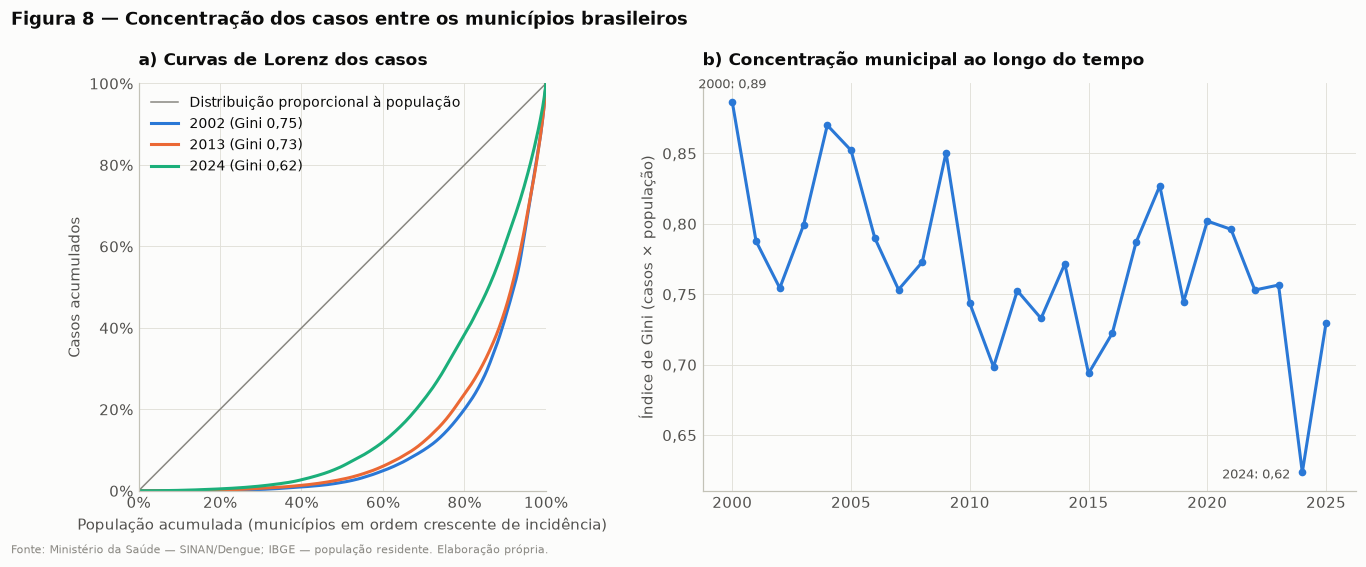

Tendência do Gini (tau de Kendall): -0,34, p = 0.016


In [22]:
anos_lorenz = [2002, 2013, 2024]
fig, (ax_curva, ax_gini) = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1, 1.25]})
ax_curva.plot([0, 100], [0, 100], color=viz.TINTA_SUAVE, linewidth=1, label="Distribuição proporcional à população")
for cor, ano in zip(viz.CATEGORICA, anos_lorenz, strict=False):
    grupo = base_municipal[base_municipal["ano_epi"] == ano]
    curva = metricas.curva_lorenz(grupo["casos"], grupo["populacao"])
    ax_curva.plot(curva["pop_acumulada"] * 100, curva["valor_acumulado"] * 100, color=cor, label=f"{ano} (Gini {viz.formatar_numero(concentracao.loc[ano, 'gini'], 2)})")
ax_curva.set_xlim(0, 100)
ax_curva.set_ylim(0, 100)
ax_curva.set_aspect("equal")
ax_curva.xaxis.set_major_formatter(viz.EIXO_PERCENTUAL)
ax_curva.yaxis.set_major_formatter(viz.EIXO_PERCENTUAL)
ax_curva.set_xlabel("População acumulada (municípios em ordem crescente de incidência)")
ax_curva.set_ylabel("Casos acumulados")
ax_curva.set_title("a) Curvas de Lorenz dos casos", fontsize=11)
ax_curva.legend(loc="upper left")

gini_completo = concentracao.loc[ANOS_COMPLETOS, "gini"]
ax_gini.plot(gini_completo.index, gini_completo.values, color=viz.CATEGORICA[0], marker="o", markersize=4)
for ano in [gini_completo.idxmax(), gini_completo.idxmin()]:
    deslocamento = (0, 9) if ano == gini_completo.idxmax() else (-8, -4)
    alinhamento = "center" if ano == gini_completo.idxmax() else "right"
    ax_gini.annotate(f"{ano}: {viz.formatar_numero(gini_completo[ano], 2)}", (ano, gini_completo[ano]), xytext=deslocamento, textcoords="offset points", ha=alinhamento, fontsize=8.5, color=viz.TINTA_SECUNDARIA)
ax_gini.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: viz.formatar_numero(valor, 2)))
ax_gini.set_ylabel("Índice de Gini (casos × população)")
ax_gini.set_title("b) Concentração municipal ao longo do tempo", fontsize=11)
fig.suptitle("Figura 8 — Concentração dos casos entre os municípios brasileiros", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
viz.salvar_figura(fig, "fig08_concentracao_municipal")
plt.show()

tendencia = stats.kendalltau(gini_completo.index, gini_completo.values)
metricas_artigo.update(
    {
        "gini_2002": round(float(concentracao.loc[2002, "gini"]), 3),
        "gini_2024": round(float(concentracao.loc[2024, "gini"]), 3),
        "gini_max_ano": int(gini_completo.idxmax()),
        "gini_min_ano": int(gini_completo.idxmin()),
        "pct_municipios_com_casos_2002": round(float(concentracao.loc[2002, "pct_municipios_com_casos"]), 1),
        "pct_municipios_com_casos_2024": round(float(concentracao.loc[2024, "pct_municipios_com_casos"]), 1),
        "kendall_tau_gini": round(float(tendencia.statistic), 2),
        "kendall_p_gini": float(f"{tendencia.pvalue:.2g}"),
    }
)
print(f"Tendência do Gini (tau de Kendall): {viz.formatar_numero(tendencia.statistic, 2)}, p = {tendencia.pvalue:.2g}")

A dengue continua sendo uma doença concentrada — o índice de Gini nunca fica abaixo de 0,6 —, mas a concentração caiu: de 0,89 em 2000 para 0,62 em 2024, uma tendência de queda moderada e estatisticamente significativa pelo teste de Kendall. A proporção de municípios com ao menos um caso subiu de 30% em 2000, e cerca de dois terços entre 2002 e 2008, para 98% em 2024. Ou seja, a doença deixou de ser um problema de poucos polos urbanos e passou a atingir o território quase inteiro.

### 2.2 Correlações

In [23]:
semanal_regiao = (
    tabelas["casos_semana_uf"]
    .groupby(["ano_epi", "semana_epi", "regiao"], observed=True)["casos"]
    .sum()
    .unstack("regiao")[viz.REGIOES]
)
correlacao_regioes = semanal_regiao.loc[ANOS_COMPLETOS].corr(method="spearman")
correlacao_regioes.style.format(lambda valor: viz.formatar_numero(valor, 2)).background_gradient(cmap=viz.MAPA_SEQUENCIAL, vmin=0, vmax=1)

regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
regiao,,,,,
Norte,"1,00","0,43","0,61","0,64","0,50"
Nordeste,"0,43","1,00","0,56","0,74","0,59"
Centro-Oeste,"0,61","0,56","1,00","0,86","0,82"
Sudeste,"0,64","0,74","0,86","1,00","0,86"
Sul,"0,50","0,59","0,82","0,86","1,00"


In [24]:
uf_recente = ano_uf[ano_uf["ano_epi"].between(2014, 2025) & (ano_uf["casos"] >= 1_000)]
rho, p_valor = stats.spearmanr(uf_recente["incidencia_100mil"], uf_recente["letalidade_casos_provaveis"])
metricas_artigo.update({"spearman_incidencia_letalidade": round(float(rho), 2), "spearman_incidencia_letalidade_p": float(f"{p_valor:.2g}"), "spearman_incidencia_letalidade_n": int(len(uf_recente))})
print(f"Incidência × letalidade (UF-ano, 2014–2025, n = {len(uf_recente)}): rho de Spearman = {viz.formatar_numero(rho, 2)}, p = {p_valor:.2g}")

Incidência × letalidade (UF-ano, 2014–2025, n = 298): rho de Spearman = -0,05, p = 0.39


As séries semanais das cinco regiões são positivamente correlacionadas (a sazonalidade é nacional), com correlação mais forte entre regiões vizinhas — Sudeste, Centro-Oeste e Sul, entre 0,82 e 0,86 — e mais fraca entre Norte e Nordeste (0,43), onde o regime de chuvas é diferente. Já entre incidência e letalidade nos pares UF-ano a correlação de Spearman é praticamente nula e não significativa: epidemias maiores não aumentam a proporção de óbitos entre os casos, mas, por envolverem muito mais pessoas, aumentam o número absoluto de mortes.

**Resposta à RQ2.** A dengue se expandiu geograficamente: deixou de ser concentrada no Nordeste e em alguns polos do Sudeste e do Centro-Oeste e passou a atingir com força o Sul e quase todos os municípios do país. Ainda assim, a distribuição entre municípios segue desigual, e os maiores pesos relativos estão no Centro-Oeste e no Sudeste.

## 3. RQ3 — Perfil demográfico e gravidade

Esta seção usa o período **2014–2025**, em que a classificação de casos (dengue, dengue com sinais de alarme, dengue grave) é a atual e o preenchimento dos campos é mais estável. O ano parcial de 2026 fica de fora.

In [25]:
PERIODO_PERFIL = (2014, 2025)
perfil = tabelas["perfil_demografico"]
perfil = perfil[perfil["ano_epi"].between(*PERIODO_PERFIL)]
medidas = ["casos", "casos_graves", "obitos", "hospitalizados", "hospitalizacao_informada"]

por_idade = perfil.groupby("faixa_etaria", observed=True)[medidas].sum()
letalidade_idade = metricas.proporcao_com_ic(por_idade["obitos"], por_idade["casos"]).set_index(por_idade.index) * 100
hospitalizacao_idade = metricas.proporcao_com_ic(por_idade["hospitalizados"], por_idade["hospitalizacao_informada"]).set_index(por_idade.index) * 100
gravidade_idade = metricas.proporcao_com_ic(por_idade["casos_graves"], por_idade["casos"]).set_index(por_idade.index) * 100

tabela_idade = por_idade.assign(
    letalidade_pct=letalidade_idade["proporcao"],
    hospitalizacao_pct=hospitalizacao_idade["proporcao"],
    graves_pct=gravidade_idade["proporcao"],
    obitos_por_100mil_casos=por_idade["obitos"] / por_idade["casos"] * 1e5,
)
tabela_idade

,casos,casos_graves,obitos,hospitalizados,hospitalizacao_informada,letalidade_pct,hospitalizacao_pct,graves_pct,obitos_por_100mil_casos
faixa_etaria,,,,,,,,,
<1,192099,3244,163,12801,114578,"0,08","11,17","1,69","84,85"
1-4,478307,6734,125,21573,305696,"0,03","7,06","1,41","26,13"
5-9,954275,15919,220,39202,631170,"0,02","6,21","1,67","23,05"
10-14,1284632,18399,244,42471,841346,"0,02","5,05","1,43","18,99"
15-19,1618656,20053,321,37741,1043484,"0,02","3,62","1,24","19,83"
20-29,3535390,41862,837,74664,2293169,"0,02","3,26","1,18","23,67"
30-39,3169700,39654,1122,76278,2071830,"0,04","3,68","1,25","35,40"
40-49,2753440,37243,1447,72037,1824577,"0,05","3,95","1,35","52,55"
50-59,2140256,32210,1715,65183,1431445,"0,08","4,55","1,50","80,13"


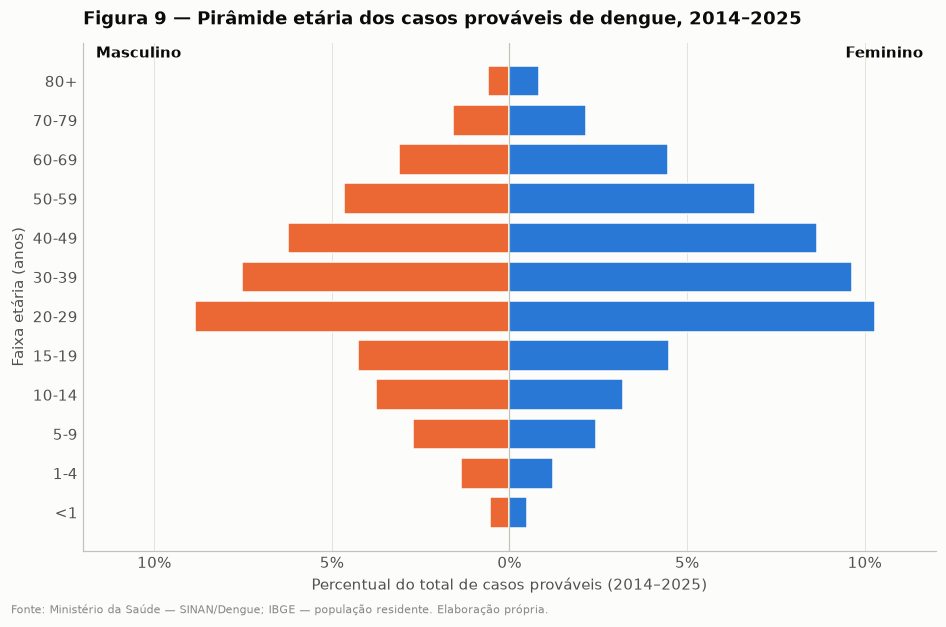

Mulheres: 54,8% dos casos; 20 a 59 anos: 62,8%.


In [26]:
piramide = (
    perfil[perfil["sexo"].isin(["Feminino", "Masculino"])]
    .groupby(["faixa_etaria", "sexo"], observed=True)["casos"]
    .sum()
    .unstack("sexo")
)
piramide_pct = piramide / piramide.to_numpy().sum() * 100
posicoes = np.arange(len(piramide_pct))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(posicoes, -piramide_pct["Masculino"], color=viz.CORES_SEXO["Masculino"], height=0.78, edgecolor=viz.SUPERFICIE, linewidth=1)
ax.barh(posicoes, piramide_pct["Feminino"], color=viz.CORES_SEXO["Feminino"], height=0.78, edgecolor=viz.SUPERFICIE, linewidth=1)
ax.set_yticks(posicoes, labels=piramide_pct.index)
limite = np.ceil(piramide_pct.to_numpy().max() + 1)
ax.set_xlim(-limite, limite)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: viz.formatar_percentual(abs(valor), 0)))
ax.axvline(0, color=viz.EIXO, linewidth=0.8)
ax.text(-limite * 0.97, len(posicoes) - 0.4, "Masculino", ha="left", fontsize=10, fontweight="bold", color=viz.TINTA)
ax.text(limite * 0.97, len(posicoes) - 0.4, "Feminino", ha="right", fontsize=10, fontweight="bold", color=viz.TINTA)
ax.set_xlabel("Percentual do total de casos prováveis (2014–2025)")
ax.set_ylabel("Faixa etária (anos)")
ax.set_title("Figura 9 — Pirâmide etária dos casos prováveis de dengue, 2014–2025")
ax.grid(axis="y", visible=False)
viz.salvar_figura(fig, "fig09_piramide_etaria")
plt.show()

pct_feminino = piramide["Feminino"].sum() / piramide.to_numpy().sum() * 100
pct_20_59 = por_idade.loc[["20-29", "30-39", "40-49", "50-59"], "casos"].sum() / por_idade["casos"].sum() * 100
metricas_artigo.update({"pct_casos_feminino": round(float(pct_feminino), 1), "pct_casos_20_59": round(float(pct_20_59), 1)})
print(f"Mulheres: {viz.formatar_percentual(pct_feminino)} dos casos; 20 a 59 anos: {viz.formatar_percentual(pct_20_59)}.")

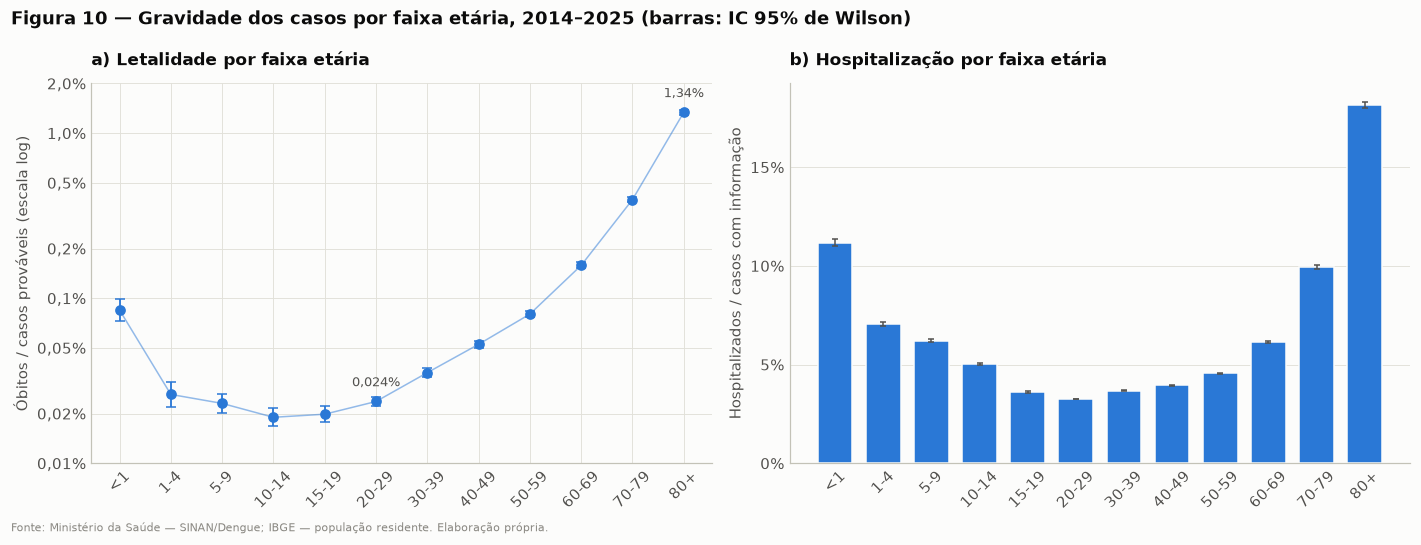

In [27]:
fig, (ax_let, ax_hosp) = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(por_idade))
rotulos = list(por_idade.index)

ax_let.errorbar(
    x, letalidade_idade["proporcao"],
    yerr=[letalidade_idade["proporcao"] - letalidade_idade["ic_inferior"], letalidade_idade["ic_superior"] - letalidade_idade["proporcao"]],
    fmt="o", color=viz.CATEGORICA[0], ecolor=viz.CATEGORICA[0], elinewidth=1.2, capsize=3, markersize=6,
)
ax_let.plot(x, letalidade_idade["proporcao"], color=viz.CATEGORICA[0], linewidth=1, alpha=0.5)
ax_let.set_yscale("log")
ax_let.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2])
ax_let.yaxis.set_minor_locator(plt.NullLocator())
ax_let.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: viz.formatar_percentual(valor, 2 if valor < 0.1 else 1)))
ax_let.set_xticks(x, labels=rotulos, rotation=45)
ax_let.set_ylabel("Óbitos / casos prováveis (escala log)")
ax_let.set_title("a) Letalidade por faixa etária", fontsize=11)
for faixa in ["20-29", "80+"]:
    i = rotulos.index(faixa)
    ax_let.annotate(viz.formatar_percentual(letalidade_idade.loc[faixa, "proporcao"], 3 if faixa == "20-29" else 2), (i, letalidade_idade.loc[faixa, "proporcao"]), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8.5, color=viz.TINTA_SECUNDARIA)

ax_hosp.bar(x, hospitalizacao_idade["proporcao"], color=viz.CATEGORICA[0], width=0.72, edgecolor=viz.SUPERFICIE, linewidth=1)
ax_hosp.errorbar(
    x, hospitalizacao_idade["proporcao"],
    yerr=[hospitalizacao_idade["proporcao"] - hospitalizacao_idade["ic_inferior"], hospitalizacao_idade["ic_superior"] - hospitalizacao_idade["proporcao"]],
    fmt="none", ecolor=viz.TINTA_SECUNDARIA, elinewidth=1, capsize=2,
)
ax_hosp.set_xticks(x, labels=rotulos, rotation=45)
ax_hosp.yaxis.set_major_locator(plt.MultipleLocator(5))
ax_hosp.yaxis.set_major_formatter(viz.EIXO_PERCENTUAL)
ax_hosp.set_ylabel("Hospitalizados / casos com informação")
ax_hosp.set_title("b) Hospitalização por faixa etária", fontsize=11)
ax_hosp.grid(axis="x", visible=False)
fig.suptitle("Figura 10 — Gravidade dos casos por faixa etária, 2014–2025 (barras: IC 95% de Wilson)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
viz.salvar_figura(fig, "fig10_gravidade_idade")
plt.show()

In [28]:
rr_idosos = metricas.risco_relativo(
    int(por_idade.loc["80+", "obitos"]), int(por_idade.loc["80+", "casos"]),
    int(por_idade.loc["20-29", "obitos"]), int(por_idade.loc["20-29", "casos"]),
)
pct_obitos_60_mais = por_idade.loc[["60-69", "70-79", "80+"], "obitos"].sum() / por_idade["obitos"].sum() * 100
pct_casos_60_mais = por_idade.loc[["60-69", "70-79", "80+"], "casos"].sum() / por_idade["casos"].sum() * 100
rho_idade, p_idade = stats.spearmanr(np.arange(len(por_idade)), letalidade_idade["proporcao"])

por_sexo = perfil[perfil["sexo"].isin(["Feminino", "Masculino"])].groupby("sexo", observed=True)[["casos", "obitos"]].sum()
contingencia = np.column_stack([por_sexo["obitos"], por_sexo["casos"] - por_sexo["obitos"]])
qui2, p_sexo, _, _ = stats.chi2_contingency(contingencia)
letalidade_sexo = por_sexo["obitos"] / por_sexo["casos"] * 100

metricas_artigo.update(
    {
        "letalidade_20_29_pct": round(float(letalidade_idade.loc["20-29", "proporcao"]), 4),
        "letalidade_80_mais_pct": round(float(letalidade_idade.loc["80+", "proporcao"]), 3),
        "rr_obito_80_mais_vs_20_29": round(rr_idosos["risco_relativo"], 1),
        "rr_ic_inferior": round(rr_idosos["ic_inferior"], 1),
        "rr_ic_superior": round(rr_idosos["ic_superior"], 1),
        "pct_obitos_60_mais": round(float(pct_obitos_60_mais), 1),
        "pct_casos_60_mais": round(float(pct_casos_60_mais), 1),
        "hospitalizacao_menor_1_ano_pct": round(float(hospitalizacao_idade.loc["<1", "proporcao"]), 1),
        "hospitalizacao_80_mais_pct": round(float(hospitalizacao_idade.loc["80+", "proporcao"]), 1),
        "hospitalizacao_20_29_pct": round(float(hospitalizacao_idade.loc["20-29", "proporcao"]), 1),
        "letalidade_masculino_pct": round(float(letalidade_sexo["Masculino"]), 4),
        "letalidade_feminino_pct": round(float(letalidade_sexo["Feminino"]), 4),
        "qui2_sexo_obito": round(float(qui2), 1),
        "p_sexo_obito": float(f"{p_sexo:.2g}"),
        "spearman_idade_letalidade": round(float(rho_idade), 2),
    }
)
print(f"Risco relativo de óbito, 80+ vs 20–29 anos: {viz.formatar_numero(rr_idosos['risco_relativo'], 1)} "
      f"(IC 95%: {viz.formatar_numero(rr_idosos['ic_inferior'], 1)} a {viz.formatar_numero(rr_idosos['ic_superior'], 1)})")
print(f"Pessoas com 60 anos ou mais: {viz.formatar_percentual(pct_casos_60_mais)} dos casos e {viz.formatar_percentual(pct_obitos_60_mais)} dos óbitos.")
print(f"Letalidade: homens {viz.formatar_percentual(letalidade_sexo['Masculino'], 3)}, mulheres {viz.formatar_percentual(letalidade_sexo['Feminino'], 3)} "
      f"(qui-quadrado = {viz.formatar_numero(qui2, 1)}, p = {p_sexo:.2g}).")
print(f"Idade × letalidade: rho de Spearman = {viz.formatar_numero(rho_idade, 2)}, p = {p_idade:.2g}.")

Risco relativo de óbito, 80+ vs 20–29 anos: 56,4 (IC 95%: 52,4 a 60,9)
Pessoas com 60 anos ou mais: 12,7% dos casos e 57,8% dos óbitos.
Letalidade: homens 0,088%, mulheres 0,073% (qui-quadrado = 127,1, p = 1.8e-29).
Idade × letalidade: rho de Spearman = 0,66, p = 0.02.


A gravidade cresce de forma acentuada com a idade. A letalidade fica em torno de 0,02% entre 10 e 29 anos e passa de 1% entre pessoas com 80 anos ou mais — um risco de óbito mais de 50 vezes maior. Pessoas com 60 anos ou mais somam cerca de 13% dos casos, mas quase 58% dos óbitos. A hospitalização tem forma de "U": é mais alta nos menores de 1 ano e nos idosos. As mulheres são maioria entre os casos, mas a letalidade é um pouco maior entre os homens, diferença estatisticamente significativa pelo teste qui-quadrado — o que, com dezenas de milhões de registros, indica uma diferença real, ainda que pequena em termos absolutos.

In [29]:
anual_gravidade = anual.loc[:, ["casos", "casos_graves", "obitos"]].copy()
anual_gravidade["letalidade"] = anual_gravidade["obitos"] / anual_gravidade["casos"] * 100
anual_gravidade["pct_graves"] = anual_gravidade["casos_graves"] / anual_gravidade["casos"] * 100

fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.12,
    subplot_titles=("Letalidade: óbitos por 100 casos prováveis (%)", "Casos com sinais de alarme ou graves (%)"),
)
for linha, coluna, formato in [(1, "letalidade", ",.3f"), (2, "pct_graves", ",.2f")]:
    fig.add_trace(
        go.Scatter(
            x=anual_gravidade.index, y=anual_gravidade[coluna], mode="lines+markers",
            line={"color": viz.CATEGORICA[0], "width": 2}, marker={"size": 7, "line": {"color": viz.SUPERFICIE, "width": 2}},
            customdata=anual_gravidade[["casos", "obitos", "casos_graves"]].to_numpy(),
            hovertemplate="<b>%{x}</b><br>%{y:" + formato + "}%<br>Casos: %{customdata[0]:,.0f}<br>Óbitos: %{customdata[1]:,.0f}<br>Graves: %{customdata[2]:,.0f}<extra></extra>",
            showlegend=False,
        ),
        row=linha, col=1,
    )
    fig.add_vrect(x0=1999.5, x1=2013.5, fillcolor=viz.GRADE, opacity=0.5, line_width=0, layer="below", row=linha, col=1)
fig.add_annotation(x=2006.5, y=1, xref="x", yref="y domain", text="Classificação anterior a 2014", showarrow=False, yanchor="top", font={"size": 11, "color": viz.TINTA_SECUNDARIA})
fig.update_yaxes(rangemode="tozero", ticksuffix="%")
fig.update_xaxes(dtick=2)
fig.update_layout(title="Figura 11 — Letalidade e proporção de casos graves por ano, 2000–2026", height=640, hovermode="closest")
viz.salvar_interativo(fig, "fig11_letalidade_gravidade_anual")
fig.show()

A Figura 11 exige cautela na leitura: até 2013 a classificação de gravidade era outra (dengue com complicações, febre hemorrágica e síndrome do choque), mais restritiva que a atual, por isso as séries não são diretamente comparáveis antes e depois de 2014. Dentro do período atual, a proporção de casos com sinais de alarme ou graves sobe de forma contínua desde 2021 (de cerca de 1% para mais de 2% em 2025 e 2026), e a letalidade de 2025 (0,11%) é a maior de toda a série — movimento que coincide com a volta do sorotipo DENV-3, analisada a seguir. A letalidade de 2026 ainda deve subir, porque parte dos óbitos do ano continua em investigação.

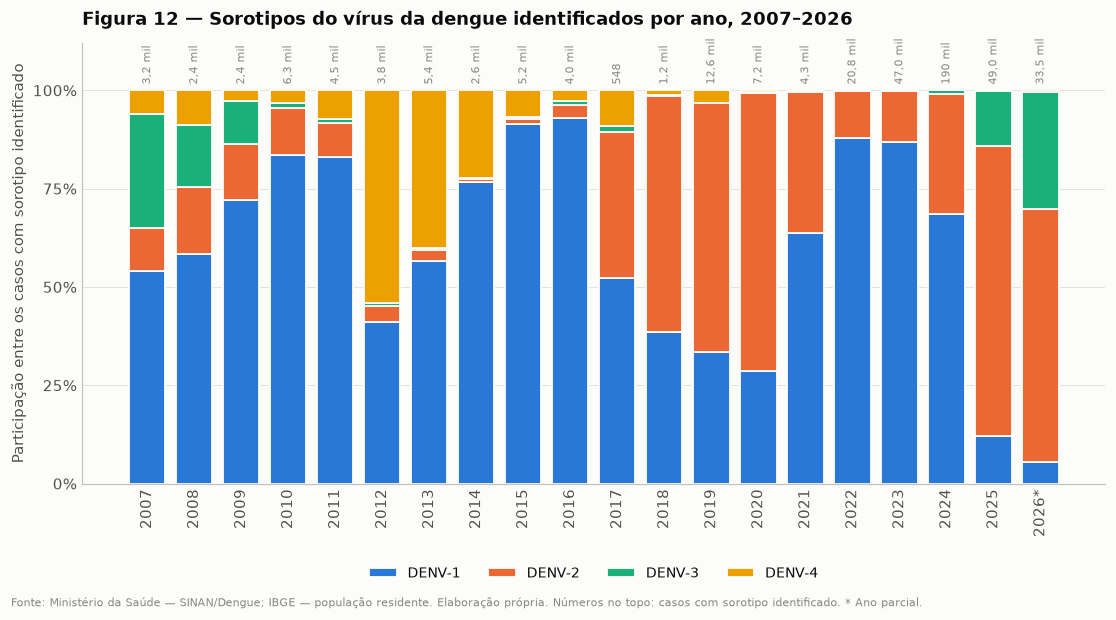

sorotipo,DENV-1,DENV-2,DENV-3,DENV-4
ano_epi,,,,
2013,"56,60","2,80","0,60","40,10"
2014,"76,60","0,70","0,40","22,30"
2015,"91,50","1,30","0,40","6,80"
2016,"93,00","3,30","1,00","2,70"
2017,"52,20","37,20","1,60","8,90"
2018,"38,70","59,80","0,40","1,10"
2019,"33,40","63,40","0,10","3,10"
2020,"28,70","70,70","0,00","0,50"
2021,"63,70","36,00","0,10","0,20"


In [30]:
sorotipos = tabelas["sorotipos"]
sorotipos_ano = sorotipos[sorotipos["ano_epi"] >= 2007].groupby(["ano_epi", "sorotipo"], observed=True)["casos"].sum().unstack("sorotipo", fill_value=0)[viz.SOROTIPOS]
sorotipos_pct = sorotipos_ano.div(sorotipos_ano.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 5.2))
base = np.zeros(len(sorotipos_pct))
for sorotipo in viz.SOROTIPOS:
    ax.bar(sorotipos_pct.index, sorotipos_pct[sorotipo], bottom=base, color=viz.CORES_SOROTIPO[sorotipo], label=sorotipo, width=0.78, edgecolor=viz.SUPERFICIE, linewidth=1.2)
    base += sorotipos_pct[sorotipo].to_numpy()
for ano, total in sorotipos_ano.sum(axis=1).items():
    ax.text(ano, 101.5, viz.formatar_compacto(total), ha="center", va="bottom", fontsize=7.5, color=viz.TINTA_SUAVE, rotation=90)
ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 25))
ax.yaxis.set_major_formatter(viz.EIXO_PERCENTUAL)
ax.set_xticks(sorotipos_pct.index, labels=[f"{ano}*" if ano in config.PARTIAL_YEARS else str(ano) for ano in sorotipos_pct.index], rotation=90)
ax.set_ylabel("Participação entre os casos com sorotipo identificado")
ax.set_title("Figura 12 — Sorotipos do vírus da dengue identificados por ano, 2007–2026")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
ax.grid(axis="x", visible=False)
viz.salvar_figura(fig, "fig12_sorotipos", fonte=f"{viz.FONTE_SINAN} Números no topo: casos com sorotipo identificado. * Ano parcial.")
plt.show()

metricas_artigo.update(
    {
        "denv3_pct_2024": round(float(sorotipos_pct.loc[2024, "DENV-3"]), 1),
        "denv3_pct_2025": round(float(sorotipos_pct.loc[2025, "DENV-3"]), 1),
        "denv3_pct_2026": round(float(sorotipos_pct.loc[2026, "DENV-3"]), 1),
        "denv2_pct_2025": round(float(sorotipos_pct.loc[2025, "DENV-2"]), 1),
        "denv1_pct_2023": round(float(sorotipos_pct.loc[2023, "DENV-1"]), 1),
    }
)
sorotipos_pct.round(1).loc[2013:]

Os sorotipos se alternam em ondas: DENV-4 aparece com força em 2012–2013, DENV-1 domina entre 2014 e 2016 e de novo entre 2021 e 2024, DENV-2 predomina entre 2018 e 2020 e volta a ser maioria em 2025. O dado mais relevante para a vigilância é o **retorno do DENV-3**, que circulou até o fim dos anos 2000, ficou praticamente ausente desde 2010 e passa de cerca de 1% dos casos tipados em 2024 para 14% em 2025 e 30% em 2026. Como crianças e jovens nascidos depois desse período não tiveram contato com esse sorotipo, há uma grande população suscetível, e uma segunda infecção por sorotipo diferente aumenta o risco de dengue grave. Os números no topo das barras lembram que só uma pequena fração dos casos tem o sorotipo identificado.

In [31]:
raca = tabelas["casos_raca_cor"]
raca = raca[raca["ano_epi"].between(*PERIODO_PERFIL)].groupby("raca", observed=True)[["casos", "obitos"]].sum()
raca["pct_casos"] = raca["casos"] / raca["casos"].sum() * 100
raca["letalidade_pct"] = raca["obitos"] / raca["casos"] * 100
metricas_artigo["pct_raca_ignorada"] = round(float(raca.loc["Ignorada", "pct_casos"]), 1)
raca

,casos,obitos,pct_casos,letalidade_pct
raca,,,,
Branca,7086889,7510,"38,31","0,11"
Preta,781719,637,"4,23","0,08"
Amarela,181062,156,"0,98","0,09"
Parda,6210686,4544,"33,57","0,07"
Indígena,43521,46,"0,24","0,11"
Ignorada,4196727,1799,"22,68","0,04"


A análise por raça/cor fica limitada pela alta proporção de registros sem a informação (mais de um quinto dos casos de 2014 a 2025), e a letalidade muito menor no grupo "ignorada" sugere que o campo é mais bem preenchido justamente nos casos graves e nos óbitos, que passam por investigação detalhada. Por isso, diferenças entre os grupos não são interpretadas como diferenças de risco.

**Resposta à RQ3.** A dengue atinge sobretudo adultos em idade ativa e um pouco mais as mulheres, mas o óbito se concentra nos idosos: a letalidade cresce de forma quase exponencial a partir dos 50 anos. A hospitalização é mais frequente nas duas pontas da vida. A gravidade recente aumentou junto com a reintrodução do DENV-3, o que reforça a importância da vigilância laboratorial dos sorotipos.

## 4. Síntese e limitações

| Pergunta | Principal achado |
|---|---|
| RQ1 — Tempo | Epidemias a cada 2–3 anos, sempre entre fevereiro e maio; 2024 foi o único ano atípico, com incidência quase 4 vezes o recorde anterior e pico mais de 6 vezes acima do limite do canal endêmico |
| RQ2 — Espaço | Expansão para o Sul e para quase todos os municípios; a concentração municipal (Gini) caiu de forma consistente, mas continua alta |
| RQ3 — Pessoas | Casos concentrados em adultos e mulheres; óbitos concentrados em idosos (risco mais de 50 vezes maior aos 80+ do que aos 20–29); retorno do DENV-3 a partir de 2025 |

**Limitações**

- **Subnotificação:** o SINAN registra apenas os casos que chegaram a um serviço de saúde e foram notificados; casos leves ou assintomáticos ficam de fora, e o grau de subnotificação muda entre anos e lugares.
- **Mudanças de sistema e de classificação:** os quatro leiautes do SINAN e a nova classificação de 2014 limitam a comparação da gravidade antes e depois de 2014.
- **Arquivos já filtrados:** alguns anos são publicados sem os casos descartados; a análise usa casos prováveis justamente para manter a comparabilidade.
- **Denominadores:** a população de 2007 e 2023 foi interpolada, e as estimativas intercensitárias foram revistas pelo IBGE após o Censo 2022.
- **2026 parcial:** os dados vão até a data de extração e as últimas semanas ainda serão completadas pelo atraso de notificação.
- **Sorotipo:** identificado em uma fração pequena e variável dos casos, o que torna as proporções sensíveis à estratégia de testagem de cada ano e estado.

In [32]:
metricas_artigo["gerado_em"] = pd.Timestamp.now(tz="America/Sao_Paulo").strftime("%Y-%m-%d")
caminho_metricas = config.ASSETS_DIR / "dados" / "metricas.json"
caminho_metricas.parent.mkdir(parents=True, exist_ok=True)
caminho_metricas.write_text(json.dumps(metricas_artigo, ensure_ascii=False, indent=2), encoding="utf-8")
pd.Series(metricas_artigo).to_frame("valor")

,valor
registros_lidos,32512002
casos_provaveis_periodo,26364939
removidos_descartados,6146531
removidos_duplicidade,430
casos_2024,6564941
...,...
denv3_pct_2026,"29,80"
denv2_pct_2025,"73,80"
denv1_pct_2023,"86,90"
pct_raca_ignorada,"22,70"
